# Iniciación en Python con Aplicaciones en Aceración (module 05)

**Dr. Edgar Ivan Castro Cedeño**

[edgar.castro@cinvestav.mx](mailto:edgar.castro@cinvestav.mx)

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.interpolate import interp1d

from src.enthalpy import c2k, k2c, dHdt
from src.enthalpy import create_h_T_interpolators

# 1. Modelo de capacitancia agrupada

## 1.1 Formulación entálpica

**La tasa neta de calentamiento/enfriamiento del sólido, es igual a la tasa neta de transferencia de calor a través de su superficie circundante.**

$$V \rho \frac{\partial h}{\partial t} = A_{\mathrm{conv}} \cdot q_{\mathrm{conv}} + A_{\mathrm{rad}} \cdot q_{\mathrm{rad}}$$



<details>
<summary><b>Nomenclatura</b></summary>

<div class="alert alert-info">

- **$A_{\mathrm{conv}}$**: Área superficial de intercambio convectivo, $[\mathrm{m^2}]$.

- **$A_{\mathrm{rad}}$**: Área superficial de intercambio radiativo, $[\mathrm{m^2}]$.

- **$h$**: Entalpía específica, $[\mathrm{J.kg^{-1}}]$.

- **$q_{\mathrm{conv}}$**: Flujo de calor convectivo, $[\mathrm{W.m^{-2}}]$.

- **$q_{\mathrm{rad}}$**: Flujo de calor radiativo, $[\mathrm{W.m^{-2}}]$.

- **$t$**: tiempo, $[\mathrm{s}]$.

- **$V$**: Volúmen, $[\mathrm{m^{3}}]$.

- **$\rho$**: Densidad, $[\mathrm{kg.m^{-3}}]$.

</div>

</details>

<details>
<summary><b>Dimensiones / Unidades </b></summary>

<div class="alert alert-info">

$$\mathrm{\underbrace{\left[{m^3} \right]\left[\frac{kg}{m^3} \right]\left[\frac{J}{kg.s} \right]}_{\displaystyle \mathrm{\left[{W}\right]}}} = \mathrm{\underbrace{\left[{m^2} \right]\left[\frac{J}{m^2.s} \right]}_{\displaystyle \mathrm{\left[{W}\right]}}} $$

</div>

</details>

Dimensiones:

$$\mathrm{\underbrace{\left[{m^3} \right]\left[\frac{kg}{m^3} \right]\left[\frac{J}{kg.s} \right]}_{\displaystyle \mathrm{\left[{W}\right]}}} = \mathrm{\underbrace{\left[{m^2} \right]\left[\frac{J}{m^2.s} \right]}_{\displaystyle \mathrm{\left[{W}\right]}}} $$

Los flujos de calor convectivos y radiativos se definen:

$$q_{\mathrm{conv}} = -h_{c} \left(T - T_{\mathrm{conv}}\right)$$

$$q_{\mathrm{rad}} = -\sigma \varepsilon F \left(T^{4} - T_{\mathrm{rad}}^{4} \right)$$

<details>
<summary><b>Nomenclatura</b></summary>

<div class="alert alert-info">

- **$F$**: Factor de vista, $[\mathrm{-}]$.

- **$h_{c}$**: Coeficiente de transferencia de calor por convección, $[\mathrm{W.m^{-2}.K^{-1}}]$.

- **$q_{\mathrm{conv}}$**: Flujo de calor convectivo, $[\mathrm{W.m^{-2}}]$.

- **$q_{\mathrm{rad}}$**: Flujo de calor radiativo, $[\mathrm{W.m^{-2}}]$.

- **$T$**: temperatura, $[\mathrm{K}]$.

- **$T_{\mathrm{conv}}$**: temperatura del entorno (convectivo), $[\mathrm{K}]$.

- **$T_{\mathrm{rad}}$**: temperatura del entorno (radiativo), $[\mathrm{K}]$.

- **$\varepsilon$**: emisividad, $[\mathrm{-}]$.

- **$\sigma$**: constante de Stefan-Boltzman, $\sigma \approx 5.67 \times 10^{-8} \, [\mathrm{W.m^{-2}.K^{-4}}]$.

</div>

</details>

## 1.2 Formulación Cp

**Tasa de enfriamiento/calentamiento de un sólido con densidad, densidad y capacidad calorífica constantes:**

$$V \rho C_{p} \frac{\partial T}{\partial t} = A_{\mathrm{conv}} \cdot q_{\mathrm{conv}} + A_{\mathrm{rad}} \cdot q_{\mathrm{rad}}$$



<details>
<summary><b>Nomenclatura</b></summary>

<div class="alert alert-info">

- **$A_{\mathrm{conv}}$**: Área superficial de intercambio convectivo, $[\mathrm{m^2}]$.

- **$A_{\mathrm{rad}}$**: Área superficial de intercambio radiativo, $[\mathrm{m^2}]$.

- **$C_{p}$**: Capacidad calorífica específica, $[\mathrm{J.kg^{-1}}]$.

- **$q_{\mathrm{conv}}$**: Flujo de calor convectivo, $[\mathrm{W.m^{-2}}]$.

- **$q_{\mathrm{rad}}$**: Flujo de calor radiativo, $[\mathrm{W.m^{-2}}]$.

- **$T$**: temperature, $[\mathrm{K}]$.

- **$t$**: tiempo, $[\mathrm{s}]$.

- **$V$**: Volúmen, $[\mathrm{m^{3}}]$.

- **$\rho$**: Densidad, $[\mathrm{kg.m^{-3}}]$.

</div>

</details>

<details>
<summary><b>Dimensiones / Unidades </b></summary>

<div class="alert alert-info">

$$\mathrm{\underbrace{\left[{m^3} \right]\left[\frac{kg}{m^3} \right]\left[\frac{J}{kg.K} \right]\left[\frac{K}{s} \right]}_{\displaystyle \mathrm{\left[{W}\right]}} = \underbrace{\left[\frac{W}{m^{2}.K} \right] \left[{m^2} \right]}_{\displaystyle \mathrm{\left[{W}\right]}}}$$

</div>

</details>

Dimensiones:

$$\mathrm{\underbrace{\left[{m^3} \right]\left[\frac{kg}{m^3} \right]\left[\frac{J}{kg.s} \right]}_{\displaystyle \mathrm{\left[{W}\right]}}} = \mathrm{\underbrace{\left[{m^2} \right]\left[\frac{J}{m^2.s} \right]}_{\displaystyle \mathrm{\left[{W}\right]}}} $$

Los flujos de calor convectivos y radiativos se definen:

$$q_{\mathrm{conv}} = -h_{c} \left(T - T_{\mathrm{conv}}\right)$$

$$q_{\mathrm{rad}} = -\sigma \varepsilon F \left(T^{4} - T_{\mathrm{rad}}^{4} \right)$$

<details>
<summary><b>Nomenclatura</b></summary>

<div class="alert alert-info">

- **$F$**: Factor de vista, $[\mathrm{-}]$.

- **$h_{c}$**: Coeficiente de transferencia de calor por convección, $[\mathrm{W.m^{-2}.K^{-1}}]$.

- **$q_{\mathrm{conv}}$**: Flujo de calor convectivo, $[\mathrm{W.m^{-2}}]$.

- **$q_{\mathrm{rad}}$**: Flujo de calor radiativo, $[\mathrm{W.m^{-2}}]$.

- **$T$**: temperatura, $[\mathrm{K}]$.

- **$T_{\mathrm{conv}}$**: temperatura del entorno (convectivo), $[\mathrm{K}]$.

- **$T_{\mathrm{rad}}$**: temperatura del entorno (radiativo), $[\mathrm{K}]$.

- **$\varepsilon$**: emisividad, $[\mathrm{-}]$.

- **$\sigma$**: constante de Stefan-Boltzman, $\sigma \approx 5.67 \times 10^{-8} \, [\mathrm{W.m^{-2}.K^{-4}}]$.

</div>

</details>

# 2. Implementación en Python

## 2.1 Crear interpoladores entalpía - temperatura

In [2]:
#%% Load h vs T data and create interpolators
h_T_table_iron = np.genfromtxt(
    fname = os.path.join("TDB","T_vs_h_Fe.txt"),
    names = True
)
h_T_table_steel = np.genfromtxt(
    fname = os.path.join("TDB","T_vs_h_steel.txt"),
    names = True
)
h_T_table_graphite = np.genfromtxt(
    fname = os.path.join("TDB","T_vs_h_C.txt"),
    names = True   
)
h_T_table_chrome = np.genfromtxt(
    fname = os.path.join("TDB","T_vs_h_Cr.txt"),
    names = True   
)
H2T_iron, T2H_iron = create_h_T_interpolators(h_T_table_iron)
H2T_steel, T2H_steel = create_h_T_interpolators(h_T_table_steel)
H2T_graph, T2H_graph = create_h_T_interpolators(h_T_table_graphite)
H2T_chrome, T2H_chrome = create_h_T_interpolators(h_T_table_chrome)

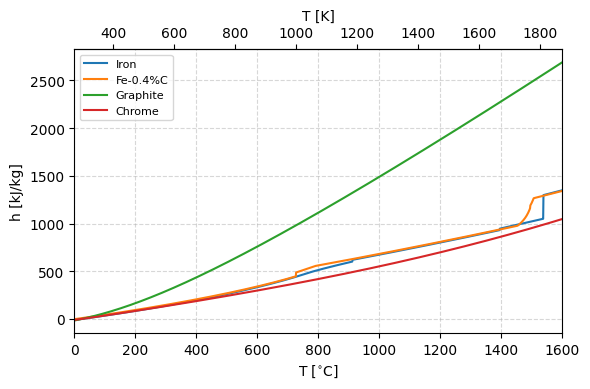

In [3]:
#%% plot h vs T using the interpolators
fig, ax = plt.subplots(figsize=(6, 4))

Tc = np.linspace(0, 1600, 1601) # temperature, [C]
T = c2k(Tc)

ax.plot(Tc, 1e-3*T2H_iron(T), label='Iron')
ax.plot(Tc, 1e-3*T2H_steel(T), label='Fe-0.4%C')
ax.plot(Tc, 1e-3*T2H_graph(T), label='Graphite')
ax.plot(Tc, 1e-3*T2H_chrome(T), label='Chrome')

ax.set_ylabel(f"h [kJ/kg]")
ax.set_xlabel(r"T [$^{\circ}$C]")
ax.set_xlim(0, 1600)
ax.grid(ls='--', alpha=0.5)
ax.legend(loc='best', fontsize=8)
secax = ax.secondary_xaxis('top', functions=(c2k, k2c))
secax.set_xlabel('T [K]')

fig.tight_layout()
plt.show()

## 2.2 Ejemplos

### 2.2.1 Condiciones constantes

Este ejemplo presenta y compara cálculos de enfriamiento bajo condiciones constantes, para dos materiales distintos, que presentan transiciones de fase.

In [4]:
#%% Calculation Pure iron (cooling)

H2T, T2H = H2T_iron, T2H_iron
########################################################### pre-processing
rho = 7500       # density, [kg/m3]
Diam = 10        # sphere diameter, [mm]
T_ini = 1600     # initial temperature, [C]
T_inf = 35       # far field temperature, [C]

A_V = 6 / (1e-3*Diam) # form factor, [1/m]

# packing of parameters
thermophysical = (rho, H2T)
geometry = A_V              # surface-area-to-volume ratio, [1/m]
convective = (15, c2k(T_inf))      # convective htc [W/(m2.K)], and far-field T [K]
radiative = (0.3, 1.0, c2k(T_inf)) # emisivity, view factor and far-field T [K]

t_span = (0, 300)        # time span (0 to 300 s)
n_steps = 600

################################################################## processing
H_init = T2H(c2k(T_ini))
sol = solve_ivp(
    fun = dHdt, 
    t_span = t_span, 
    y0 = [H_init], 
    args = (thermophysical, geometry, convective, radiative),
    method = 'Radau',
    t_eval = np.linspace(t_span[0], t_span[1], n_steps)
)

############################################################ Post-processing
t1 = sol.t
H1 = sol.y[0]
T1 = H2T(sol.y[0])

In [5]:
#%% Calculation Fe-0.4%C (cooling)

H2T, T2H = H2T_steel, T2H_steel
########################################################### pre-processing
rho = 7500       # density, [kg/m3]
Diam = 10        # sphere diameter, [mm]
T_ini = 1600     # initial temperature, [C]
T_inf = 35       # far field temperature, [C]

A_V = 6 / (1e-3*Diam) # form factor, [1/m]

# packing of parameters
thermophysical = (rho, H2T)
geometry = A_V              # surface-area-to-volume ratio, [1/m]
convective = (15, c2k(T_inf))      # convective htc [W/(m2.K)], and far-field T [K]
radiative = (0.3, 1.0, c2k(T_inf)) # emisivity, view factor and far-field T [K]

t_span = (0, 300)        # time span (0 to 300 s)
n_steps = 600

################################################################## processing
H_init = T2H(c2k(T_ini))
sol = solve_ivp(
    fun = dHdt, 
    t_span = t_span, 
    y0 = [H_init], 
    args = (thermophysical, geometry, convective, radiative),
    method = 'Radau',
    t_eval = np.linspace(t_span[0], t_span[1], n_steps)
)

############################################################ Post-processing
t2 = sol.t
H2 = sol.y[0]
T2 = H2T(sol.y[0])

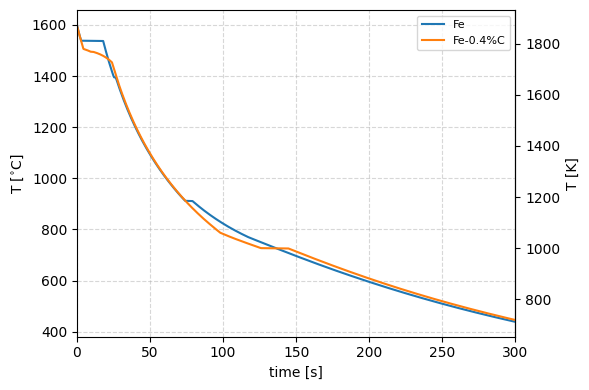

In [6]:
#%% Compare cooling curves
fig, ax = plt.subplots(figsize = (6, 4))

ax.plot(t1, k2c(T1), label='Fe')
ax.plot(t2, k2c(T2), label='Fe-0.4%C')
ax.set_xlabel('time [s]')
ax.set_xlim(t_span)
ax.set_ylabel(r"T [$^{\circ}$C]")
ax.grid(ls='--', alpha=0.5)
ax.legend(loc='best', fontsize=8)
secax = ax.secondary_yaxis('right', functions=(c2k, k2c))
secax.set_ylabel('T [K]')
fig.tight_layout()
plt.show()

### 2.2.1 Emisividad térmica dependiente de la temperatura

Este ejemplo compara cálculos de enfriamiento de un material sin transición de fase, cuya emisividad se considera constante, o dependiente de la temperatura.

In [7]:
#%% Calculation Graphite (cooling with constant emissivity)

H2T, T2H = H2T_graph, T2H_graph
########################################################### pre-processing
rho = 2200       # density, [kg/m3]
Diam = 20        # cylinder diameter, [mm]
Len = 100        # cylinder length, [mm]
T_ini = 1800     # initial temperature, [C]
T_conv = 35      # convective far-field temperature, [C]
T_rad  = 35    # radiative far-field temperature, [C]

A_V = 4 / (1e-3*Diam)  + 2 / (1e-3*Len) # form factor, [1/m]

# packing of parameters
thermophysical = (rho, H2T)
geometry = A_V              # surface-area-to-volume ratio, [1/m]
convective = (15, c2k(T_conv))      # convective htc [W/(m2.K)], and far-field T [K]
radiative = (0.7, 1.0, c2k(T_rad)) # emisivity, view factor and far-field T [K]

t_span = (0, 300)        # time span (0 to 300 s)
n_steps = 600

################################################################## processing
H_init = T2H(c2k(T_ini))
sol = solve_ivp(
    fun = dHdt, 
    t_span = t_span, 
    y0 = [H_init], 
    args = (thermophysical, geometry, convective, radiative),
    method = 'Radau',
    t_eval = np.linspace(t_span[0], t_span[1], n_steps)
)

############################################################ Post-processing
t3 = sol.t
H3 = sol.y[0]
T3 = H2T(sol.y[0])

In [8]:
#%% Calculation Graphite (cooling with emissivity as a function of temperature)

H2T, T2H = H2T_graph, T2H_graph
########################################################### pre-processing
rho = 2200       # density, [kg/m3]
Diam = 20        # cylinder diameter, [mm]
Len = 100        # cylinder length, [mm]
T_ini = 1800     # initial temperature, [C]
T_conv = 35      # convective far-field temperature, [C]
T_rad  = 35    # radiative far-field temperature, [C]

A_V = 4 / (1e-3*Diam)  + 2 / (1e-3*Len) # form factor, [1/m]

# emmisivity as a function of temperature
def emm_graph(t, T):
    """ interpolate T vs emissivity """
    return np.interp(T, [300, 1600], [0.4, 0.7])

# packing of parameters
thermophysical = (rho, H2T)
geometry = A_V              # surface-area-to-volume ratio, [1/m]
convective = (15, c2k(T_conv))      # convective htc [W/(m2.K)], and far-field T [K]
radiative = (emm_graph, 1.0, c2k(T_rad)) # emisivity, view factor and far-field T [K]

t_span = (0, 300)        # time span (0 to 300 s)
n_steps = 600

################################################################## processing
H_init = T2H(c2k(T_ini))
sol = solve_ivp(
    fun = dHdt, 
    t_span = t_span, 
    y0 = [H_init], 
    args = (thermophysical, geometry, convective, radiative),
    method = 'Radau',
    t_eval = np.linspace(t_span[0], t_span[1], n_steps)
)

############################################################ Post-processing
t4 = sol.t
H4 = sol.y[0]
T4 = H2T(sol.y[0])

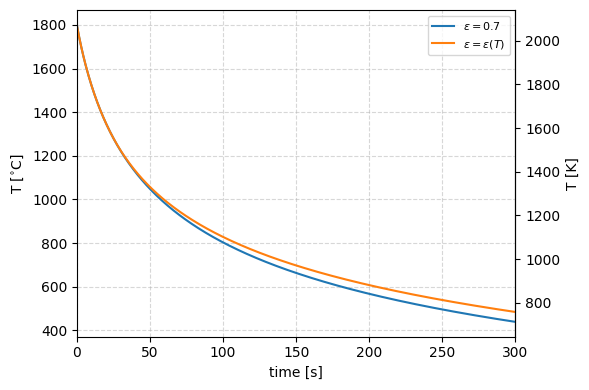

In [9]:
#%% Compare cooling curves
fig, ax = plt.subplots(figsize = (6, 4))

ax.plot(t3, k2c(T3), label=r'$\varepsilon=0.7$')
ax.plot(t4, k2c(T4), label=r'$\varepsilon=\varepsilon(T)$')
ax.set_xlabel('time [s]')
ax.set_xlim(t_span)
ax.set_ylabel(r"T [$^{\circ}$C]")
ax.grid(ls='--', alpha=0.5)
ax.legend(loc='best', fontsize=8)
secax = ax.secondary_yaxis('right', functions=(c2k, k2c))
secax.set_ylabel('T [K]')
fig.tight_layout()
plt.show()

### 2.2.3 Ciclo térmico

In [10]:
#%% Calculation Fe-0.4%C (cooling)

H2T, T2H = H2T_steel, T2H_steel
########################################################### pre-processing
rho = 7500       # density, [kg/m3]
Diam = 10        # sphere diameter, [mm]
T_ini = 35     # initial temperature, [C]

A_V = 6 / (1e-3*Diam) # form factor, [1/m]

# conversion of times
s2min = lambda t: t/60 # convert time from seconds to minutes
min2s = lambda t: t*60 # convert time from minutes to seconds

# heating/cooling ramp
thermal_cycle_times = np.array([0,   30,  60,   80,  120, 121]) # time, [min]
thermal_cycle_temps = np.array([35, 700, 900, 1200, 1200,  35]) # temperature [C]
def T_rad(t, T):
    """ give the ramp as an intepolator, t vs T """
    return np.interp(t, min2s(thermal_cycle_times), c2k(thermal_cycle_temps))
def T_conv(t, T):
    delay = 120 # delay (30 seconds)
    return T_rad((t-delay),T)



# packing of parameters
thermophysical = (rho, H2T)
geometry = A_V              # surface-area-to-volume ratio, [1/m]
convective = (15, T_rad)      # convective htc [W/(m2.K)], and far-field T [K]
radiative = (0.3, 1.0, T_conv) # emisivity, view factor and far-field T [K]

t_span = (0, 9000)        # time span (0 to 300 s)
n_steps = 9000

################################################################## processing
H_init = T2H(c2k(T_ini))
sol = solve_ivp(
    fun = dHdt, 
    t_span = t_span, 
    y0 = [H_init], 
    args = (thermophysical, geometry, convective, radiative),
    method = 'Radau',
    t_eval = np.linspace(t_span[0], t_span[1], n_steps)
)

############################################################ Post-processing
t5 = sol.t
H5 = sol.y[0]
T5 = H2T(sol.y[0])

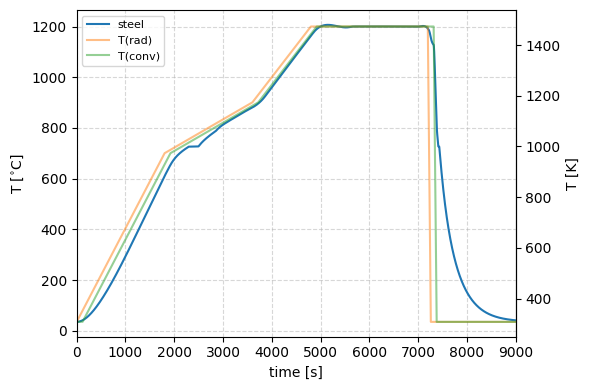

In [11]:
#%% Plot full treatment cycle
fig, ax = plt.subplots(figsize = (6, 4))

ax.plot(t5, k2c(T5), label=r'steel')
ax.plot(t5, k2c(T_rad(t5, 0.0)) , alpha=0.5, label='T(rad)')      # radiative temp
ax.plot(t5, k2c(T_conv(t5, 0.0)), alpha=0.5, label='T(conv)')      # convective temp
ax.set_xlabel('time [s]')
ax.set_xlim(t_span)
ax.set_ylabel(r"T [$^{\circ}$C]")
ax.grid(ls='--', alpha=0.5)
ax.legend(loc='best', fontsize=8)
secax = ax.secondary_yaxis('right', functions=(c2k, k2c))
secax.set_ylabel('T [K]')
fig.tight_layout()
plt.show()

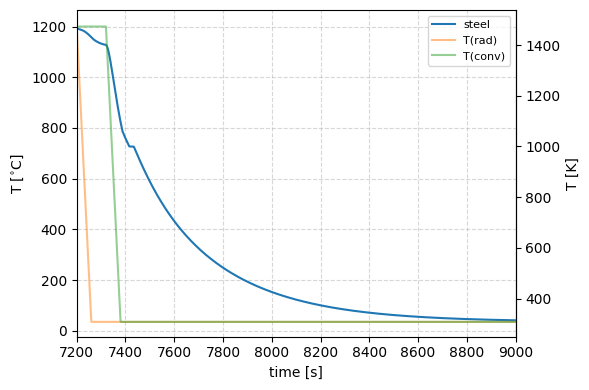

In [16]:
#%% Plot cooling cycle
fig, ax = plt.subplots(figsize = (6, 4))

ax.plot(t5, k2c(T5), label=r'steel')
ax.plot(t5, k2c(T_rad(t5, 0.0)) , alpha=0.5, label='T(rad)')      # radiative temp
ax.plot(t5, k2c(T_conv(t5, 0.0)), alpha=0.5, label='T(conv)')      # convective temp
ax.set_xlabel('time [s]')
ax.set_xlim(7200, 9000)
ax.set_ylabel(r"T [$^{\circ}$C]")
ax.grid(ls='--', alpha=0.5)
ax.legend(loc='best', fontsize=8)
secax = ax.secondary_yaxis('right', functions=(c2k, k2c))
secax.set_ylabel('T [K]')
fig.tight_layout()
plt.show()